# 05 · Uncertainty & simulasi inventori

**Tujuan notebook:** menerjemahkan forecast menjadi **keputusan stok**, lalu mengukur dampaknya dalam bahasa bisnis: berapa persen permintaan pelanggan terlayani (*fill rate*) dan berapa modal yang tertahan di gudang (nilai inventori).

**Konsep singkat** (dijelaskan lengkap di README):
- **Review period R = 7 hari:** stok dicek dan dipesan seminggu sekali.
- **Lead time L = 3 hari:** pesanan baru datang 3 hari kemudian.
- **Order-up-to level S** = forecast total 10 hari (R + L) + **safety stock**. Jumlah pesanan = S − (stok di gudang + barang di jalan), minimal 0.
- **Safety stock** = cadangan untuk menutup forecast yang meleset ke bawah. Besarnya ditentukan oleh **target service level**.
- **Fill rate** = unit terlayani / unit diminta. Asumsi **lost sales**: pelanggan yang tidak kebagian tidak kembali.

**Cara menghitung safety stock (model-agnostic, adil untuk semua model):** error kumulatif 10 hari dari fold backtest **sebelumnya** dibagi skala item (rata-rata perubahan harian di data training), diambil kuantilnya per kelas demand, lalu dikalikan kembali dengan skala item. Periode F2 dikalibrasi dari F1, F3 dari F1–F2, F4 dari F1–F3, dan test dari F1–F4. Tidak ada informasi dari periode yang sedang dievaluasi. Mirip *split conformal prediction*.

Hasil dibaca dari `python -m scripts.run_inventory_sim` (`reports/results/inventory_*.csv`).

In [1]:
import numpy as np
import pandas as pd
import plotly.io as pio

from forecasting.config import load_config, resolve_path
from forecasting.inventory.run import (
    inventory_at_fill_rate,
    item_classes,
    load_forecasts,
    run_policy,
    sim_periods,
)
from forecasting.validation.backtest import load_level_data
from forecasting.viz import plots

pio.renderers.default = "png"
pio.renderers["png"].width = 1000
pd.set_option("display.float_format", "{:,.3f}".format)

config = load_config()
inv = config["inventory"]
RESULTS = resolve_path(config, "results")
summary = pd.read_csv(RESULTS / "inventory_summary.csv")
items_kpi = pd.read_parquet(RESULTS / "inventory_items.parquet")
coverage = pd.read_csv(RESULTS / "interval_coverage.csv")
CLASS_ORDER = ["smooth", "erratic", "intermittent", "lumpy"]
periods, _ = sim_periods(config)
pd.DataFrame(
    {
        "asumsi": [
            "review period R",
            "lead time L",
            "periode proteksi R + L",
            "target service level",
            "holding cost",
            "periode simulasi",
            "kebijakan stok",
            "stok awal",
        ],
        "nilai": [
            f"{inv['review_period_days']} hari",
            f"{inv['lead_time_days']} hari",
            f"{inv['review_period_days'] + inv['lead_time_days']} hari",
            ", ".join(f"{s:g}" for s in inv["service_levels"]),
            f"{inv['holding_cost_rate_annual']:.0%} nilai barang per tahun",
            f"{', '.join(p.name for p in periods)} (d_{periods[0].valid_start}–d_{periods[-1].valid_end}, "
            f"{periods[-1].valid_end - periods[0].valid_start + 1} hari)",
            "(R, S) periodic review, order-up-to, lost sales",
            "S pada hari pertama",
        ],
    }
)

,asumsi,nilai
0,review period R,7 hari
1,lead time L,3 hari
2,periode proteksi R + L,10 hari
3,target service level,"0.8, 0.85, 0.9, 0.95, 0.975, 0.99"
4,holding cost,25% nilai barang per tahun
5,periode simulasi,"F2, F3, F4, TEST (d_1830–d_1941, 112 hari)"
6,kebijakan stok,"(R, S) periodic review, order-up-to, lost sales"
7,stok awal,S pada hari pertama


## 1 · Apakah interval prediksinya jujur?

> **Coverage** = persentase jendela 10 hari yang permintaan aktualnya ≤ forecast + safety stock. Interval P90 yang jujur seharusnya "menutupi" sekitar 90% kasus. Kalau coverage jauh di bawah target, safety stock kekecilan dan toko sering kehabisan. Kalau jauh di atas target, stok berlebih.

**Insight:**
- **Interval LightGBM paling dekat ke target** di periode CV: P80 → 80,1–80,8%, P90 → 90,1–90,9%, P95 → 95,0–95,5%. **Catatan:** angka CV ini agak terlalu optimis untuk LightGBM, karena hyperparameter-nya dipilih memakai F1–F4 juga.
- MA28 dan Seasonal Naive sedikit **under-cover** (P80 hanya 76–79%). 
- **Di test, semua model under-cover**, dan LightGBM (P90 87,6%, P80 76,5%) **tidak lebih baik dari Seasonal Naive** (P90 88,2%, P80 77,6%). Arahnya sejalan dengan bias under-forecast yang membesar di test (notebook 04).
- Per kelas (tabel kedua, P90 LightGBM): 88–92% di semua kelas pada periode CV. Di test, erratic (85,2%), lumpy (86,3%), dan intermittent (87,6%) masing-masing turun ±3 poin dari F4, sedangkan smooth naik (92,0%).

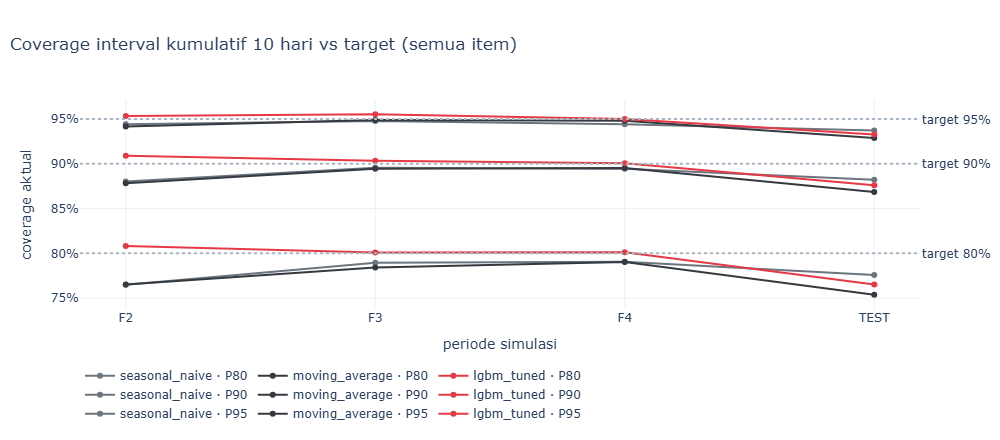

period                  F2    F3    F4  TEST
model          level                        
lgbm_tuned     0.800 0.808 0.801 0.801 0.765
               0.900 0.909 0.903 0.901 0.876
               0.950 0.953 0.955 0.950 0.933
moving_average 0.800 0.765 0.784 0.790 0.754
               0.900 0.878 0.894 0.895 0.869
               0.950 0.942 0.949 0.948 0.929
seasonal_naive 0.800 0.765 0.790 0.791 0.776
               0.900 0.880 0.896 0.894 0.882
               0.950 0.944 0.948 0.944 0.937

In [2]:
cov_all = coverage[(coverage["subset"] == "all") & (coverage["demand_class"] == "semua")]
fig = plots.plot_coverage(
    cov_all, title="Coverage interval kumulatif 10 hari vs target (semua item)"
)
fig.show()
plots.save_png(fig, "33_interval_coverage", config)
cov_all.pivot_table(index=["model", "level"], columns="period", values="coverage")

In [3]:
# Coverage per demand class at the 90% level, LightGBM, all items
c = coverage[
    (coverage["subset"] == "all")
    & (coverage["model"] == "lgbm_tuned")
    & (coverage["level"] == 0.9)
    & (coverage["demand_class"] != "semua")
]
c.pivot_table(index="demand_class", columns="period", values="coverage").reindex(CLASS_ORDER)

period,F2,F3,F4,TEST
demand_class,,,,
smooth,0.916,0.914,0.892,0.920
erratic,0.915,0.912,0.881,0.852
intermittent,0.906,0.902,0.904,0.876
lumpy,0.919,0.904,0.893,0.863


## 2 · Figur utama: trade-off fill rate vs nilai inventori

Setiap titik adalah satu target service level (0,80 … 0,99). Sumbu x = rata-rata nilai stok harian di gudang (unit × harga jual), dan sumbu y = fill rate yang benar-benar tercapai di simulasi. **Kurva yang lebih ke kiri-atas lebih efisien**: fill rate sama dengan modal lebih kecil.

Tabel di bawah membandingkan model pada **fill rate yang sama** (interpolasi linear antar titik), bukan pada target yang sama. Ini perbandingan yang adil, karena target yang sama bisa menghasilkan fill rate berbeda antar-model.

**Insight:**
- **LightGBM vs Seasonal Naive:** untuk fill rate 97%, kebijakan berbasis LightGBM butuh rata-rata inventori **$157,3 ribu**, **8,3% lebih rendah** dibanding Seasonal Naive ($171,6 ribu), atau sekitar $14,2 ribu modal yang tidak perlu tertahan. Di fill rate 95% penghematannya 10,2%, dan menyempit ke 4,2% di 99%.
- **LightGBM vs MA28: praktis sama** (+0,3% sampai −1,8%). Peningkatan akurasi WRMSSE 4,7% di notebook 03 **tidak** berubah menjadi penghematan inventori yang berarti. Safety stock ditentukan **ekor atas error kumulatif 10 hari**, bukan rata-rata error harian. Diukur di F2–F4, kuantil P95 error 10 hari (ternormalisasi) LightGBM vs MA28: intermittent −2%, lumpy −3%, erratic −7%, tetapi smooth **+9%**. Jadi keunggulan akurasi tidak selalu terbawa ke ekor yang menentukan stok. Ini hubungan yang terukur, bukan bukti sebab-akibat.
- Fill rate aktual selalu **lebih tinggi** dari target service level (target 0,80 → fill rate 93–94%). Target service level mengukur peluang stok **cukup untuk seluruh 10 hari**. Fill rate mengukur **unit**: saat stok habis di hari ke-9, sebagian besar unit sudah terlayani di hari-hari sebelumnya.

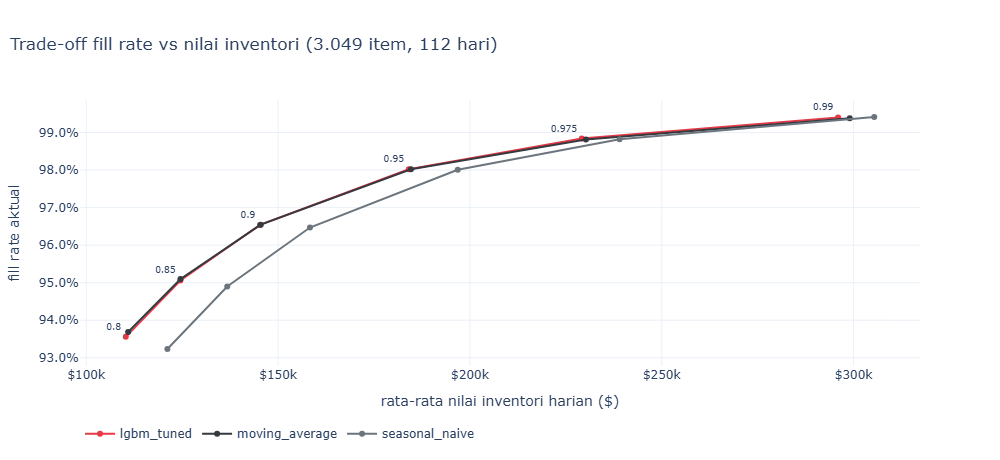

model,lgbm_tuned,moving_average,seasonal_naive,lgbm vs SN (%),lgbm vs MA28 (%)
fill_rate,,,,,
0.950,"123,964.400","123,614.600","138,115.600",-10.200,0.300
0.970,"157,327.600","157,519.800","171,569.700",-8.300,-0.100
0.980,"183,500.000","184,062.800","196,587.800",-6.700,-0.300
0.990,"248,003.300","252,646.100","258,941.100",-4.200,-1.800


In [4]:
curves = summary[(summary["subset"] == "all") & (summary["demand_class"] == "semua")]
fig = plots.plot_tradeoff(
    curves, title="Trade-off fill rate vs nilai inventori (3.049 item, 112 hari)"
)
fig.show()
plots.save_png(fig, "34_tradeoff_all_items", config)
targets = [0.95, 0.97, 0.98, 0.99]
need = inventory_at_fill_rate(curves, targets).pivot(
    index="fill_rate", columns="model", values="avg_inventory_value"
)
need["lgbm vs SN (%)"] = 100 * (need["lgbm_tuned"] / need["seasonal_naive"] - 1)
need["lgbm vs MA28 (%)"] = 100 * (need["lgbm_tuned"] / need["moving_average"] - 1)
need.round(1)

## 3 · Di 200 item sampel: LightGBM vs SARIMAX

**Insight:** tidak ada pemenang yang konsisten. LightGBM lebih hemat di fill rate 97% (−1,1%), sedangkan SARIMAX lebih hemat di 95% (LightGBM +3,0%), 98% (+0,8%), dan 99% (+3,5%). SARIMAX menang di 3 dari 4 titik, tetapi selisihnya kecil untuk sampel 200 item dan belum diuji signifikansinya. Keduanya mengalahkan Seasonal Naive di fill rate 95–98%, sedangkan di 99% LightGBM butuh 2,9% lebih banyak dari Seasonal Naive.

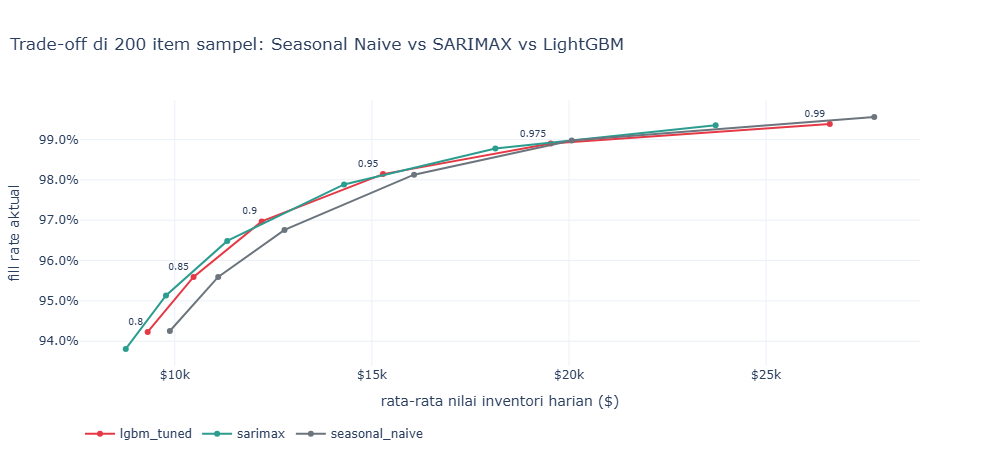

model,lgbm_tuned,sarimax,seasonal_naive,lgbm vs SARIMAX (%),lgbm vs SN (%)
fill_rate,,,,,
0.950,"9,968.300","9,674.500","10,557.700",3.000,-5.600
0.970,"12,284.300","12,420.100","13,363.000",-1.100,-8.100
0.980,"14,912.400","14,790.000","15,765.700",0.800,-5.400
0.990,"21,031.100","20,317.300","20,435.900",3.500,2.900


In [5]:
curves_s = summary[(summary["subset"] == "stat_sample") & (summary["demand_class"] == "semua")]
fig = plots.plot_tradeoff(
    curves_s, title="Trade-off di 200 item sampel: Seasonal Naive vs SARIMAX vs LightGBM"
)
fig.show()
plots.save_png(fig, "35_tradeoff_sample", config)
need_s = inventory_at_fill_rate(curves_s, targets).pivot(
    index="fill_rate", columns="model", values="avg_inventory_value"
)
need_s["lgbm vs SARIMAX (%)"] = 100 * (need_s["lgbm_tuned"] / need_s["sarimax"] - 1)
need_s["lgbm vs SN (%)"] = 100 * (need_s["lgbm_tuned"] / need_s["seasonal_naive"] - 1)
need_s.round(1)

## 4 · Ke mana perginya modal inventori?

**Insight:**
- **Item intermittent menyerap 66% nilai inventori** (±$105 ribu dari total ±$159 ribu kalau tiap kelas mencapai fill rate 97%). Sebagai pembanding, kelas ini 72% dari jumlah item dan 60% dari revenue, jadi porsinya sedikit di atas porsi revenue. 
- Di kelas ini LightGBM paling membantu: −9,7% vs Seasonal Naive dan −1,5% vs MA28. Di item **lumpy**, LightGBM −3,8% vs MA28, keunggulan terbesarnya terhadap MA28.
- Di item **smooth** dan **erratic**, LightGBM justru butuh inventori 1,4–1,7% **lebih banyak** dari MA28, walaupun akurasi hariannya lebih baik.

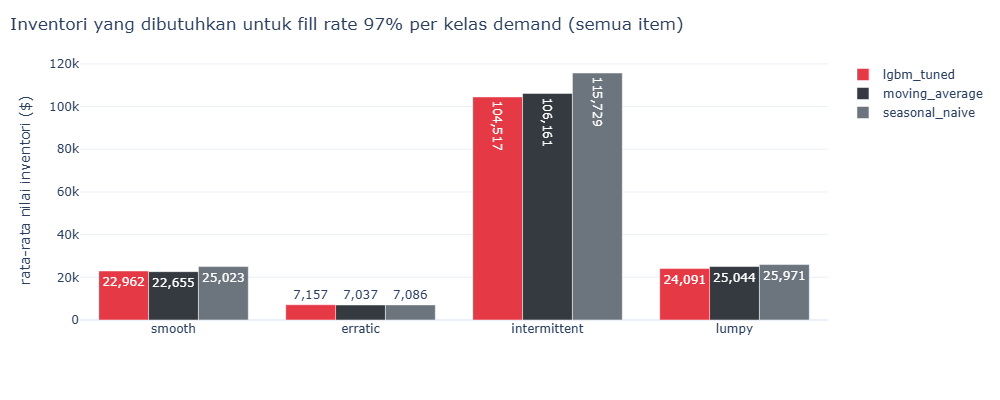

model,lgbm_tuned,moving_average,seasonal_naive,porsi inventori (lgbm),lgbm vs SN (%),lgbm vs MA28 (%)
demand_class,,,,,,
smooth,"22,962.324","22,654.628","25,022.748",0.145,-8.234,1.358
erratic,"7,156.532","7,036.995","7,086.019",0.045,0.995,1.699
intermittent,"104,516.950","106,160.728","115,729.194",0.658,-9.688,-1.548
lumpy,"24,091.101","25,044.324","25,971.322",0.152,-7.240,-3.806


In [6]:
cls = summary[(summary["subset"] == "all") & (summary["demand_class"].isin(CLASS_ORDER))]
need_c = inventory_at_fill_rate(cls, [0.97], by=["model", "demand_class"])
need_c["demand_class"] = pd.Categorical(need_c["demand_class"], CLASS_ORDER)
need_c = need_c.sort_values(["demand_class", "model"])
fig = plots.plot_metric_by_group(
    need_c.rename(columns={"avg_inventory_value": "inventori ($)"}),
    "demand_class",
    "inventori ($)",
    axis_title="rata-rata nilai inventori ($)",
    title="Inventori yang dibutuhkan untuk fill rate 97% per kelas demand (semua item)",
)
fig.update_traces(texttemplate="%{y:,.0f}")
fig.show()
plots.save_png(fig, "36_inventory_by_class", config)
piv = need_c.pivot(index="demand_class", columns="model", values="avg_inventory_value")
piv["porsi inventori (lgbm)"] = piv["lgbm_tuned"] / piv["lgbm_tuned"].sum()
piv["lgbm vs SN (%)"] = 100 * (piv["lgbm_tuned"] / piv["seasonal_naive"] - 1)
piv["lgbm vs MA28 (%)"] = 100 * (piv["lgbm_tuned"] / piv["moving_average"] - 1)
piv

## 5 · Harga sebuah service level

Tabel ini memakai kebijakan LightGBM di semua item.

**Insight, keputusan bisnis terbesar di project ini:** menaikkan target service level jauh lebih mahal daripada perbedaan antar-model.
- Dari target 0,95 ke 0,99, fill rate hanya naik dari 98,0% ke 99,4% (+1,4 poin), tapi nilai inventori naik **61%** ($184 ribu → $296 ribu).
- Dibandingkan target 0,80, target 0,99 butuh inventori **2,7×** lipat.
- Sebagai perbandingan, selisih LightGBM dan Seasonal Naive pada fill rate yang sama hanya 4–10%.

Artinya, sebelum memperdebatkan model mana yang dipakai, manajemen perlu menentukan dulu **berapa fill rate yang benar-benar dibutuhkan** dan berapa harga stockout dibanding biaya simpan.

In [7]:
lg = curves[curves["model"] == "lgbm_tuned"].sort_values("level")
lg = lg.assign(
    **{
        "inventori vs 0,80 (x)": lg["avg_inventory_value"] / lg["avg_inventory_value"].iloc[0],
        "stockout item-hari": lg["stockout_days"],
        "unit hilang": lg["lost"],
    }
)
lg[
    [
        "level",
        "fill_rate",
        "avg_inventory_value",
        "holding_cost",
        "inventori vs 0,80 (x)",
        "stockout item-hari",
        "unit hilang",
    ]
].reset_index(drop=True)

,level,fill_rate,avg_inventory_value,holding_cost,"inventori vs 0,80 (x)",stockout item-hari,unit hilang
0,0.800,0.936,"110,294.261","8,460.930",1.000,10423,"32,863.000"
1,0.850,0.951,"124,522.749","9,552.430",1.129,7676,"25,204.000"
2,0.900,0.965,"145,263.427","11,143.496",1.317,5054,"17,654.000"
3,0.950,0.980,"184,068.637","14,120.334",1.669,2563,"10,091.000"
4,0.975,0.988,"229,146.473","17,578.360",2.078,1304,"5,909.000"
5,0.990,0.994,"295,954.637","22,703.369",2.683,571,"3,046.000"


## 6 · Contoh simulasi harian

> **Catatan data:** contoh per item disamarkan (nama generik, hari relatif, dan indeks dengan rata-rata = 100) karena aturan kompetisi M5 tidak mengizinkan publikasi datanya.

Dua item dengan volume median di kelasnya (bukan dipilih yang paling bagus). Garis biru = stok di akhir hari. Segitiga hijau = pesanan datang (3 hari setelah review mingguan). Batang abu-abu = permintaan. Batang merah = penjualan hilang karena stok habis.

Pola gigi gergaji di item smooth adalah perilaku normal kebijakan (R, S): stok naik saat barang datang, lalu turun mengikuti permintaan sampai pengiriman berikutnya. Stockout hanya terjadi sesekali, saat permintaan di akhir siklus lebih tinggi dari perkiraan. Di item lumpy, stok cadangan sering menganggur lama di gudang menunggu lonjakan permintaan yang jarang datang.

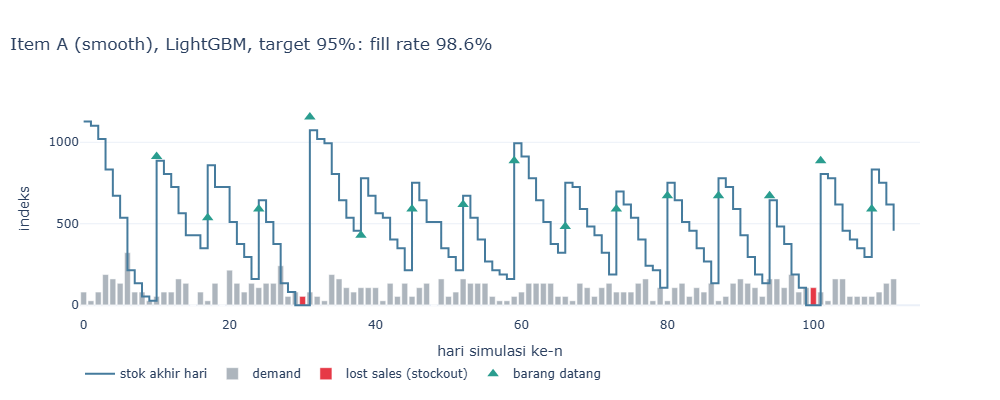

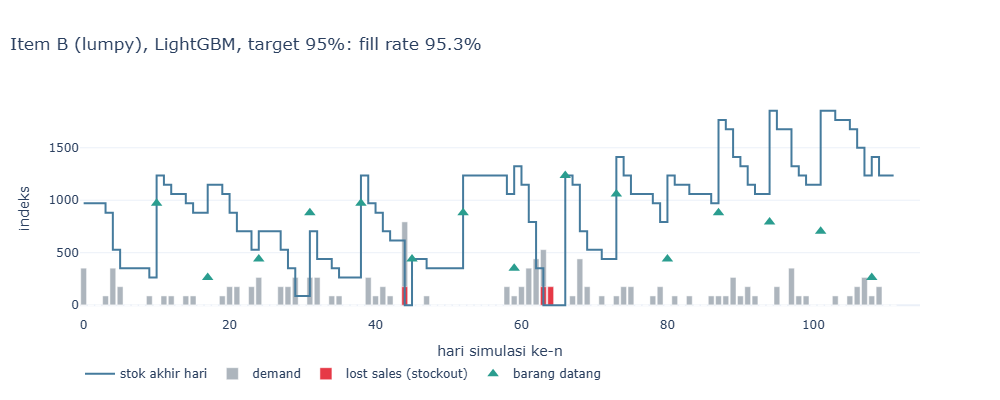

In [8]:
from forecasting.viz.anonymize import index_base, item_label, relative_days, to_index

history = load_level_data(config, "item", include_test=True)
classes = item_classes(config)
k = items_kpi[
    (items_kpi["subset"] == "all")
    & (items_kpi["model"] == "lgbm_tuned")
    & (items_kpi["level"] == 0.95)
]


def median_item(cls: str) -> str:
    pool = k[(k["demand_class"] == cls) & (k["demand"] > 0)].sort_values("demand")
    return str(pool.iloc[len(pool) // 2]["series_id"])  # median-volume item, not cherry-picked


example = [median_item("smooth"), median_item("lumpy")]
runs, _ = run_policy(
    config, load_forecasts(config, "lgbm_tuned"), history, [0.95], pd.Index(example)
)
run = runs[0.95]
dates = history.drop_duplicates("d").set_index("d")["date"].reindex(run.days).to_numpy()
for i, (item, name) in enumerate(
    zip(example, ["37a_inventory_trace_smooth", "37b_inventory_trace_lumpy"], strict=True)
):
    base = index_base(run.demand[i])
    trace = pd.DataFrame(
        {
            "date": relative_days(dates, dates[0]),
            "on_hand": to_index(run.sim["on_hand"][i], base),
            "demand": to_index(run.demand[i], base),
            "lost": to_index(run.sim["lost"][i], base),
            "received": to_index(run.sim["received"][i], base),
        }
    )
    fill = run.sim["served"][i].sum() / max(run.demand[i].sum(), 1)
    fig = plots.plot_inventory_trace(
        trace, title=f"{item_label(i, classes[item])}, LightGBM, target 95%: fill rate {fill:.1%}"
    )
    fig.update_xaxes(title_text="hari simulasi ke-n")
    fig.update_yaxes(title_text="indeks")
    fig.show()
    plots.save_png(fig, name, config)

## 7 · Profil kebijakan per kelas demand

Kebijakan LightGBM dengan target 95%, semua item. **Hari tutupan stok** = rata-rata stok dibagi rata-rata permintaan harian (berapa hari stok bisa bertahan tanpa pengiriman baru).

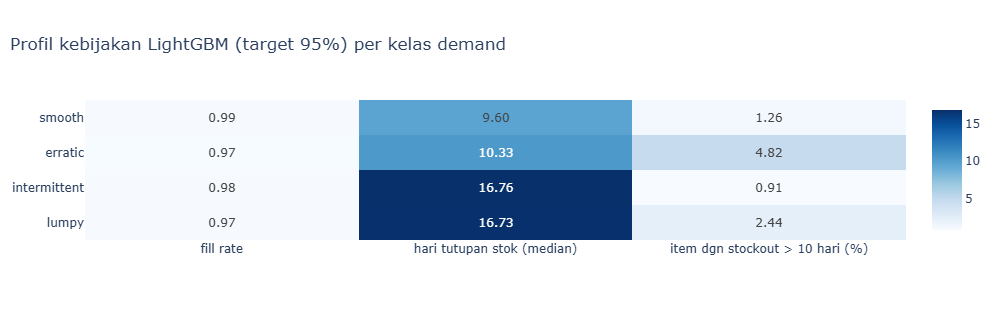

,fill rate,hari tutupan stok (median),item dgn stockout > 10 hari (%),inventori ($)
demand_class,,,,
smooth,0.989,9.605,1.255,"31,958.171"
erratic,0.968,10.334,4.819,"6,866.069"
intermittent,0.980,16.763,0.912,"119,884.673"
lumpy,0.974,16.733,2.439,"25,359.725"


In [9]:
k = items_kpi[(items_kpi["subset"] == "all") & (items_kpi["level"] == 0.95)].copy()
k["daily_demand"] = k["demand"] / len(run.days)
g = k.groupby(["demand_class", "model"], observed=True)
rec = pd.DataFrame(
    {
        "fill rate": g["served"].sum() / g["demand"].sum(),
        "hari tutupan stok (median)": g.apply(
            lambda x: (x["avg_on_hand"] / x["daily_demand"].replace(0, np.nan)).median(),
            include_groups=False,
        ),
        "item dgn stockout > 10 hari (%)": g.apply(
            lambda x: 100 * (x["stockout_days"] > 10).mean(), include_groups=False
        ),
        "inventori ($)": g["avg_inventory_value"].sum(),
    }
).reset_index()
rec["demand_class"] = pd.Categorical(rec["demand_class"], CLASS_ORDER)
rec = rec.sort_values(["demand_class", "model"])
table = rec[rec["model"] == "lgbm_tuned"].drop(columns="model").set_index("demand_class")
fig = plots.plot_heatmap(
    table[["fill rate", "hari tutupan stok (median)", "item dgn stockout > 10 hari (%)"]],
    fmt=".2f",
    colorscale="Blues",
    title="Profil kebijakan LightGBM (target 95%) per kelas demand",
)
fig.show()
plots.save_png(fig, "38_policy_profile_by_class", config)
table

**Insight:** item smooth hanya perlu ±9,6 hari tutupan stok untuk fill rate 98,9%, sedangkan intermittent dan lumpy perlu ±16,7 hari untuk fill rate 98,0% dan 97,4%. Item erratic paling sering kehabisan: 4,8% item mengalami **total** lebih dari 10 hari stockout selama 112 hari (tidak harus beruntun).

## Key findings & rekomendasi bisnis

**Temuan (dari simulasi 3.049 item × 112 hari):**
1. **Kebijakan berbasis LightGBM lebih hemat dari Seasonal Naive, tetapi tidak dari MA28.** Untuk fill rate 97%, rata-rata inventori $157,3 ribu vs $171,6 ribu (**−8,3%**). Terhadap MA28 selisihnya hanya −0,1% (95%: +0,3%, 99%: −1,8%).
2. **Interval LightGBM paling dekat ke target di CV** (P90 90–91%), tetapi angka itu agak optimis karena tuning memakai fold yang sama. Di test coverage P90 turun ke 87,6% dan tidak lebih baik dari Seasonal Naive (88,2%).
3. **Service level adalah tuas biaya terbesar.** Target 0,95 → 0,99 menaikkan inventori 61% untuk tambahan fill rate 1,4 poin.
4. **Item intermittent menyerap 66% modal inventori** (72% item, 60% revenue).

**Tiga rekomendasi:**
1. **Ganti perencanaan "salin minggu lalu" dengan kebijakan berbasis forecast.** Penghematannya 8–10% modal inventori di fill rate 95–97%. MA28 memberi hampir semua manfaat itu dengan biaya jauh lebih kecil; LightGBM layak dipakai kalau akurasi harian dan forecast agregat juga dibutuhkan.
2. **Uji target service level yang berbeda per kelas demand.** Item smooth murah dijaga di target tinggi, sedangkan intermittent/lumpy butuh tutupan stok jauh lebih lama. Kebijakan campuran ini **belum disimulasikan**.
3. **Kalibrasi ulang safety stock berkala dan pantau bias.** Coverage P90 semua model turun ke 87–88% di test. Manfaat kalibrasi ulang yang lebih sering **belum diuji**.

**Keterbatasan:**
- **Censored demand:** data berisi penjualan, bukan permintaan. Permintaan saat stok kosong di toko asli tidak tercatat, sehingga fill rate simulasi bisa terlalu optimis.
- **Asumsi tetap:** R = 7, L = 3 (pasti, tanpa variasi), holding cost 25%, nilai stok memakai harga jual (bukan harga pokok), tanpa minimum order dan masa kedaluwarsa.
- **Stok dalam unit bulat:** S dibulatkan ke atas. Versi pertama notebook ini memakai stok pecahan; kesimpulannya sama, tetapi angkanya bergeser (D-031).
- **Satu toko, 112 hari**, tanpa uji signifikansi antar-model. Jendela test ikut dipakai di simulasi ini.